## Skaidrītes skudriņas 5. posms 
#### Aprēķināt, kā laikā mainās svārsta leņkis, un salīdzinām divas diferenciālvienādojumu risināšanas metodes
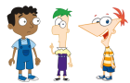

In [78]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# 1. Parameters
g = 9.81
L = 1.0      
a = 0.0 

In [79]:
# 2. 1. diferenciālās kārtas sistēma
def f(t, y):
    dy1 = y[1]
    dy2 = (g*np.sin(y[0]) - a*np.cos(y[0])) / L
    return np.array([dy1, dy2])

In [80]:
# 3. Euler metode
def eulerSolve(f, tspan, y0, h):
    t = np.arange(tspan[0], tspan[1] + h/2, h)
    y = np.zeros((len(t), len(y0)))
    y[0] = y0
    for n in range(len(t) - 1):
        y[n+1] = y[n] + h * f(t[n], y[n])
    return t, y

In [81]:
# 4. Aprēķins
y0 = np.array([0.05, 0.0])
t1, y1 = eulerSolve(f, [0, 0.5], y0, 0.05)
t2, y2 = eulerSolve(f, [0, 0.5], y0, 0.01)
sol = solve_ivp(f, [0, 0.5], y0, max_step=0.01)

In [82]:
# 5. θ pie t = 0.5 s
print("Euler h=0.05:", y1[-1, 0])
print("Euler h=0.01:", y2[-1, 0])
print("solve_ivp:   ", sol.y[0, -1])

Euler h=0.05: 0.11161502770151527
Euler h=0.01: 0.12188772589140133
solve_ivp:    0.12485167209339933


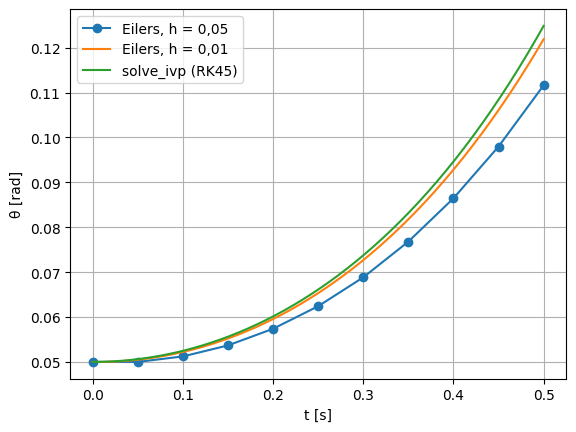

In [83]:
# 6. Grafiki :)
plt.plot(t1, y1[:, 0], "o-", label="Eilers, h = 0,05")
plt.plot(t2, y2[:, 0], label="Eilers, h = 0,01")
plt.plot(sol.t, sol.y[0], label="solve_ivp (RK45)")
plt.xlabel("t [s]")
plt.ylabel("θ [rad]")
plt.legend()
plt.grid(True)
plt.show()